# پیش‌بینی احساس نظرات دیجی‌کالا — نسخهٔ Stacking
**ساختار مدل**
1. مدل متنی (TF-IDF کلمه‌ای + کاراکتری ← Logistic Regression) با cross-validation احتمال‌های out-of-fold می‌سازد.
2. مدل دوم (Gradient Boosting) روی «۳ احتمال متنی + Score» آموزش می‌بیند تا تعامل متن و نمره را یاد بگیرد.
3. وزن هر کلاس (آستانهٔ تصمیم) روی داده‌ی out-of-fold تنظیم می‌شود تا macro-F1 بیشینه شود (بیشتر برای کلاس خنثی).

خروجی: احتمال منفی / خنثی / مثبت.

In [1]:
# !pip install pandas scikit-learn scipy joblib matplotlib
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (classification_report, confusion_matrix,ConfusionMatrixDisplay, f1_score, accuracy_score)

## ۱. بارگذاری داده و ساخت برچسب

In [4]:
df = pd.read_csv('digikala_sentiment.csv')
df = df.dropna(subset=['Text', 'Suggestion'])

# 2: مثبت ، 1: خنثی ، 0: منفی
label_map = {1: 2, 2: 1, 3: 0}
label_names = {0: 'منفی', 1: 'خنثی', 2: 'مثبت'}
df['label'] = df['Suggestion'].map(label_map)
df = df.dropna(subset=['label'])
df['label'] = df['label'].astype(int)
# errors='coerce' => to nan  اگر غیرقابل تبدیل بود
df['Score'] = pd.to_numeric(df['Score'], errors='coerce')
score_median = float(df['Score'].median())
df['Score'] = df['Score'].fillna(score_median)

# Score تقریباً فقط ضرایب ۴ است؛ مقدارهای نادر (82, 90, 94, 98) به نزدیک‌ترین ضریب ۴ برده می‌شوند
def snap_score(s):
    return np.clip(np.round(np.asarray(s, dtype=float) / 4) * 4, 0, 100)

df['Score'] = snap_score(df['Score'])

print(df['label'].value_counts(), '\n')
# درصد هر برچسب در هر Score (به‌صورت سطری)
# normalize='index' => برای هر سطر، درصدها را نسبت به مجموع همان سطر محاسبه کن
(pd.crosstab(df['Score'], df['label'].map(label_names), normalize='index') * 100).round(0)

label
2    2382
0     460
1     419
Name: count, dtype: int64 



label,خنثی,مثبت,منفی
Score,,,
0.0,5.0,41.0,54.0
4.0,0.0,0.0,100.0
8.0,0.0,0.0,100.0
12.0,25.0,0.0,75.0
16.0,8.0,8.0,85.0
20.0,9.0,4.0,87.0
24.0,18.0,0.0,82.0
28.0,0.0,4.0,96.0
32.0,0.0,0.0,100.0


## ۲. پیش‌پردازش متن فارسی

In [5]:
AR2FA = str.maketrans({'ي': 'ی', 'ك': 'ک', 'ۀ': 'ه', 'ة': 'ه', 'ؤ': 'و', 'أ': 'ا', 'إ': 'ا'})
DIGITS = str.maketrans('۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩', '01234567890123456789')
DIACRITICS = re.compile(r'[\u064B-\u0652\u0640]')
REPEAT = re.compile(r'(.)\1{2,}')  # عاااالی -> عالی

def normalize(text):
    text = str(text).translate(AR2FA).translate(DIGITS)
    text = DIACRITICS.sub('', text)
    text = text.replace('\u200c', ' ')          # نیم‌فاصله
    # یه نمونه از کاراکتر رو نگه میدارد
    text = REPEAT.sub(r'\1', text)
    text = re.sub(r'[^\w\s!؟?]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

df['clean'] = df['Text'].apply(normalize)

## ۳. تعریف اجزای Stacking

In [6]:
N_FOLDS = 5
SEED = 42

def make_text_pipe():
    return Pipeline([
        # FeatureUnion => خروجی این دو را کنار هم قرار می‌دهد
        ('tfidf', FeatureUnion([
            # هم یه کلمه ای و هم دو کلمه ای
            # کلماتی که حداقل در دو سطر دیده نشده ان حذف شوند
            # sublinear_tf=True => به جای استفاده مستقیم از تعداد تکرار یک کلمه، اثر تکرار را به صورت لگاریتمی کاهش می‌دهد
            ('word', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
            ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=3, sublinear_tf=True)),
        ])),
        ('clf', LogisticRegression(max_iter=3000, C=3.0, class_weight='balanced')),
    ])

def make_meta():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                          l2_regularization=1.0, random_state=SEED)

def meta_X(text_probs, scores):
    return np.column_stack([text_probs, np.asarray(scores, dtype=float)])

# برای هر داده، احتمال کلاس‌ها را با مدلی حساب کنیم که آن داده را در زمان آموزش ندیده است
def oof_meta(Xm, y, sw, skf):
    oof = np.zeros((len(y), 3))
    for tr, va in skf.split(Xm, y):
        m = make_meta().fit(Xm[tr], y[tr], sample_weight=sw[tr])
        oof[va] = m.predict_proba(Xm[va])
    return oof

def find_weights(proba, y):
    """وزن کلاس‌ها [منفی، خنثی، مثبت=1] را برای بیشینه‌کردن macro-F1 پیدا می‌کند."""
    grid = np.arange(0.5, 4.01, 0.25)
    best_f1, best_w = -1, np.array([1.0, 1.0, 1.0])
    for w_neg in grid:
        for w_neu in grid:
            w = np.array([w_neg, w_neu, 1.0])
            f1 = f1_score(y, (proba * w).argmax(axis=1), average='macro')
            if f1 > best_f1:
                best_f1, best_w = f1, w
    return best_w, best_f1

def fit_stack(texts, scores, y):
    y = np.asarray(y)
    skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)

    # ۱) احتمال‌های out-of-fold مدل متنی
    text_oof = cross_val_predict(make_text_pipe(), texts, y, cv=skf, method='predict_proba')
    Xm = meta_X(text_oof, scores)
    # برای هر نمونه یک وزن
    sw = compute_sample_weight('balanced', y)

    # ۲) وزن کلاس‌ها روی خروجی out-of-fold مدل دوم
    meta_oof = oof_meta(Xm, y, sw, skf)
    weights, cv_f1 = find_weights(meta_oof, y)

    # ۳) مدل‌های نهایی
    text_pipe = make_text_pipe().fit(texts, y)
    meta = make_meta().fit(Xm, y, sample_weight=sw)
    print(f'class weights [neg, neu, pos] = {weights},  CV macro-F1 = {cv_f1:.3f}')
    return {'text_pipe': text_pipe, 'meta': meta, 'weights': weights, 'score_median': score_median}

def stack_proba(model, texts, scores):
    """برمی‌گرداند: (احتمال خام، احتمال با وزن کلاس‌ها نرمال‌شده)"""
    tp = model['text_pipe'].predict_proba(texts)
    raw = model['meta'].predict_proba(meta_X(tp, scores))
    adj = raw * model['weights']
    # نرمال سازی
    # axis=1: مجموع هر سطر
    adj = adj / adj.sum(axis=1, keepdims=True)
    return raw, adj

## ۴. تقسیم داده و آموزش

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df[['clean', 'Score']], df['label'], test_size=0.2, stratify=df['label'], random_state=SEED
)
y_test = y_test.values

model = fit_stack(X_train['clean'], X_train['Score'], y_train)

class weights [neg, neu, pos] = [0.5 0.5 1. ],  CV macro-F1 = 0.644


## ۵. ارزیابی و مقایسه

فقط متن                      accuracy=0.769  macro-F1=0.586
Stacking (بدون وزن کلاس)     accuracy=0.798  macro-F1=0.691
Stacking + وزن کلاس‌ها       accuracy=0.827  macro-F1=0.673

              precision    recall  f1-score   support

        منفی      0.723     0.793     0.756        92
        خنثی      0.400     0.310     0.349        84
        مثبت      0.906     0.925     0.915       477

    accuracy                          0.827       653
   macro avg      0.676     0.676     0.673       653
weighted avg      0.815     0.827     0.820       653



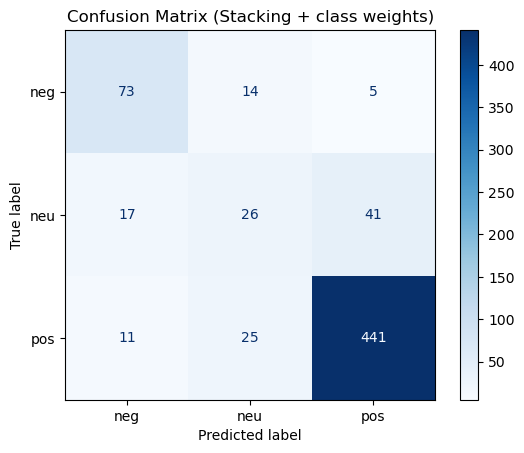

In [8]:
# مدل پایه: فقط متن
base = make_text_pipe().fit(X_train['clean'], y_train)
pred_base = base.predict(X_test['clean'])

raw, adj = stack_proba(model, X_test['clean'], X_test['Score'])
pred_raw = raw.argmax(axis=1)
pred_adj = adj.argmax(axis=1)

def row(name, pred):
    print(f'{name:<28} accuracy={accuracy_score(y_test, pred):.3f}  macro-F1={f1_score(y_test, pred, average="macro"):.3f}')

row('فقط متن', pred_base)
row('Stacking (بدون وزن کلاس)', pred_raw)
row('Stacking + وزن کلاس‌ها', pred_adj)

print()
print(classification_report(y_test, pred_adj, target_names=[label_names[i] for i in range(3)], digits=3))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_adj),
                       display_labels=['neg', 'neu', 'pos']).plot(cmap='Blues')
plt.title('Confusion Matrix (Stacking + class weights)')
plt.show()

## ۶. تابع پیش‌بینی احتمالی

In [7]:
def predict_proba(texts, scores=None, model=model):
    """texts: متن یا لیست متن — scores: عدد یا لیست عدد (۰ تا ۱۰۰).
    اگر scores داده نشود، میانهٔ داده‌ی آموزش جایگزین می‌شود (دقت کمتر)."""
    if isinstance(texts, str):
        texts = [texts]
    if scores is None:
        scores = [model['score_median']] * len(texts)
    elif np.isscalar(scores):
        scores = [scores] * len(texts)
    scores = snap_score(scores)
    clean = [normalize(t) for t in texts]
    _, adj = stack_proba(model, clean, scores)
    out = pd.DataFrame(adj, columns=['منفی', 'خنثی', 'مثبت'])
    out.insert(0, 'Score', scores)
    out.insert(0, 'متن', texts)
    # در هر سطر، اسم ستونی که بیشترین مقدار را دارد پیدا کن
    out['پیش‌بینی'] = out[['منفی', 'خنثی', 'مثبت']].idxmax(axis=1)
    return out.round(4)

samples = [
    'این اولین تجربه من برای خرید ایفون هست امروز',
    'خرید این محصول رو توصیه میکنم',
    '1 ساله این گوشی رو دارم هیچ نقطه ضعفی ازش ندیدم',
    'کیفیتش افتضاح بود پولتون رو هدر ندید',
    'بد نیست ولی چیز خاصی هم نداره',
]
sample_scores = [100, 84, 60, 10, 52]
predict_proba(samples, sample_scores)

,متن,Score,منفی,خنثی,مثبت,پیش‌بینی
0,این اولین تجربه من برای خرید ایفون هست امروز,100.0,0.0096,0.0699,0.9205,مثبت
1,خرید این محصول رو توصیه میکنم,84.0,0.1302,0.1591,0.7108,مثبت
2,1 ساله این گوشی رو دارم هیچ نقطه ضعفی ازش ندیدم,60.0,0.0431,0.1679,0.7890,مثبت
3,کیفیتش افتضاح بود پولتون رو هدر ندید,8.0,0.9664,0.0187,0.0149,منفی
4,بد نیست ولی چیز خاصی هم نداره,52.0,0.7428,0.2394,0.0178,منفی


## ۷. آموزش نهایی روی کل داده و ذخیره مدل

In [9]:
final_model = fit_stack(df['clean'], df['Score'], df['label'])
joblib.dump(final_model, 'sentiment_stacking.joblib')
print('saved: sentiment_stacking.joblib')

class weights [neg, neu, pos] = [0.5 0.5 1. ],  CV macro-F1 = 0.644
saved: sentiment_stacking.joblib


### استفاده از مدل ذخیره‌شده در آینده
```python
final_model = joblib.load('sentiment_stacking.joblib')
predict_proba('گوشی عالیه', 90, model=final_model)
```
توابع `normalize`، `snap_score`، `meta_X`، `stack_proba` و `predict_proba` (و کلاس‌های ساخته‌شده با `make_text_pipe` / `make_meta`) باید در همان محیط تعریف شده باشند.